In [300]:
import warnings
warnings.filterwarnings('ignore')

In [301]:
import arabic_reshaper
from bidi.algorithm import get_display

def fix_arabic(text):
    reshaped_text = arabic_reshaper.reshape(text)
    return get_display(reshaped_text)


> exampl of what fix arabic do

In [302]:
import matplotlib.pyplot as plt
import numpy as np

Text(0.5, 1.0, 'ﺩﻮﻛ ﺕﻻﺎﻘﻣ ﻲﻓ ﺹﻮﺼﻨﻟﺍ ﻝﻮﻃ ﻊﻳﺯﻮﺗ')

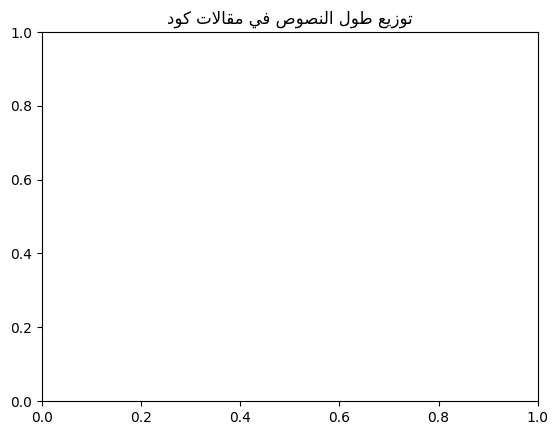

In [303]:
# Instead of this, which will render backwards:
plt.title("توزيع طول النصوص في مقالات كود")

# You do this:
plt.title(fix_arabic("توزيع طول النصوص في مقالات كود"))


In [304]:
import pandas as pd

In [305]:
df = pd.read_csv("QA-Labled-Data_final.csv", encoding="utf-8")

# 1. convertir le fichier final en JSON 

> done


In [ ]:


# # Lire le fichier CSV
# df = pd.read_csv("source_path_to_file.csv", encoding="utf-8")

# # Convertir en JSON
# df.to_json("QA-Labled-Data_final.json",force_ascii=False, orient="records", indent=4)

# print("Conversion terminée : QA-Labled-Data_final.json créé")

In [307]:
# ====== code to convert json to csv =======


# # Lire le fichier JSON
# df = pd.read_json("source_path_to_file.json", encoding="utf-8")

# df.to_csv("save_path_of_file.csv", index=False, encoding="utf-8")

# print("Conversion terminée ")


# 2. vérfication des debuts des questions pour voir les questions interdits 


In [308]:
df.head()

,id,context,Question,Answer,debut_question
0,1,حصلت “كود” على تفاصيل اتهام مصطفى لخصم رئيس جم...,شنو هي التهمة اللي موجهة لمصطفى لخصم رئيس جماع...,اختلاس وتبديد أموال عمومية,شنو
1,2,فتصريح لقناة العربية، قال مستشار شؤون الشرق ال...,فأما قناة عطى مسعد بولس التصريح ديالو؟,قناة العربية,فأما
2,3,أكد المجلس الاقتصادي والاجتماعي والبيئي أن الأ...,شكون هي الجهة اللي أكدات بلي الأجهزة الكهربائي...,المجلس الاقتصادي والاجتماعي والبيئي,شكون
3,4,علمت “كود” أن غرفة الجنح التلبسية بالمحكمة الا...,أما محكمة قررات تأخر أول جلسة ديال محاكمة إليا...,المحكمة الابتدائية بمدينة الجديدة,أما
4,5,أفادت نادية فتاح علوي، وزيرة الاقتصاد والمالية...,على حساب أما قانون تقدر الحكومة تأطر الأسعار؟,قانون حرية الأسعار والمنافسة,على


> - top20

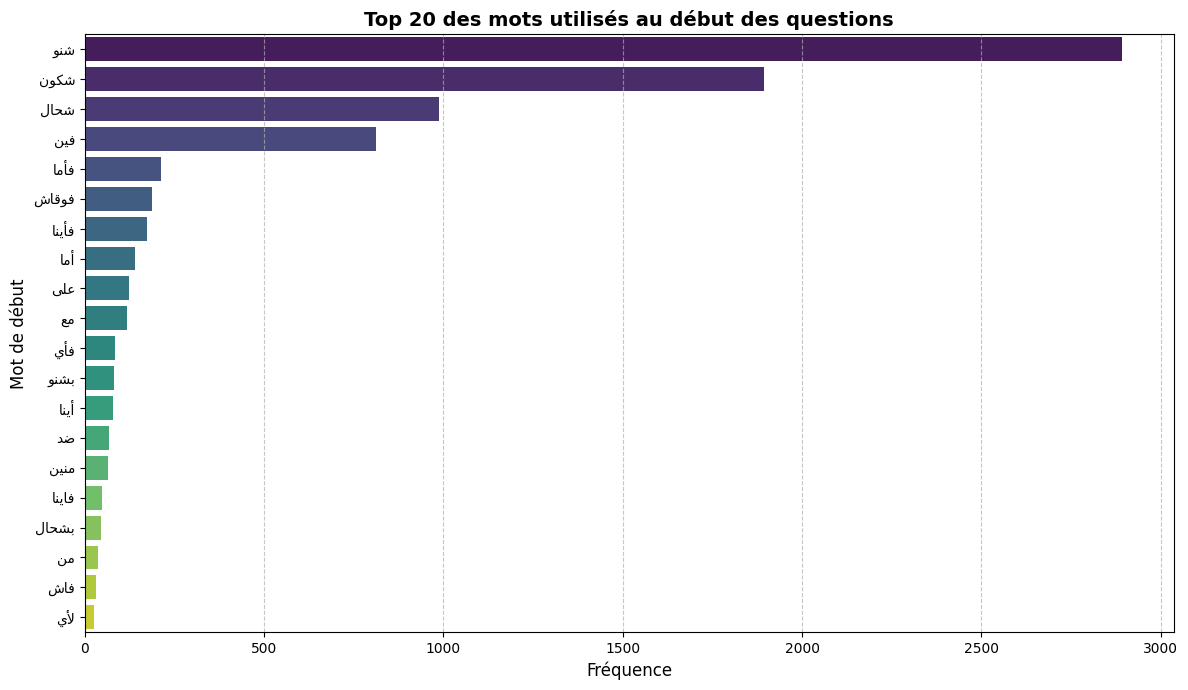

In [309]:
import matplotlib.pyplot as plt
import seaborn as sns

# Remplacez 'Question' par le nom exact de la colonne contenant vos questions
colonne_question = 'Question'

# Extraire le premier mot de chaque question (On gère les valeurs nulles et on met en minuscules pour standardiser)
df['debut_question'] = df[colonne_question].dropna().apply(
    lambda x: str(x).strip().split()[0].lower() if pd.notnull(x) and len(str(x).strip()) > 0 else None
)

# Compter les occurrences des premiers mots et garder le Top 20
top_debuts = df['debut_question'].value_counts().head(20)

# Appliquer fix_arabic à chaque label en utilisant une compréhension de liste
fixed_labels = [fix_arabic(label) for label in top_debuts.index]

# Visualiser les résultats
plt.figure(figsize=(12, 7))
sns.barplot(x=top_debuts.values, y=fixed_labels, palette='viridis')

plt.title('Top 20 des mots utilisés au début des questions', fontsize=14, fontweight='bold')
plt.xlabel('Fréquence', fontsize=12)
plt.ylabel('Mot de début', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [310]:
df.head()


,id,context,Question,Answer,debut_question
0,1,حصلت “كود” على تفاصيل اتهام مصطفى لخصم رئيس جم...,شنو هي التهمة اللي موجهة لمصطفى لخصم رئيس جماع...,اختلاس وتبديد أموال عمومية,شنو
1,2,فتصريح لقناة العربية، قال مستشار شؤون الشرق ال...,فأما قناة عطى مسعد بولس التصريح ديالو؟,قناة العربية,فأما
2,3,أكد المجلس الاقتصادي والاجتماعي والبيئي أن الأ...,شكون هي الجهة اللي أكدات بلي الأجهزة الكهربائي...,المجلس الاقتصادي والاجتماعي والبيئي,شكون
3,4,علمت “كود” أن غرفة الجنح التلبسية بالمحكمة الا...,أما محكمة قررات تأخر أول جلسة ديال محاكمة إليا...,المحكمة الابتدائية بمدينة الجديدة,أما
4,5,أفادت نادية فتاح علوي، وزيرة الاقتصاد والمالية...,على حساب أما قانون تقدر الحكومة تأطر الأسعار؟,قانون حرية الأسعار والمنافسة,على


> - Les nombre des questions uniques
> - les valeurs uniques des debut des questions

In [311]:
df['debut_question'].unique()

array(['شنو', 'فأما', 'شكون', 'أما', 'على', 'شحال', 'فوقاش', 'فين', 'مع',
       'أنا', 'فأينا', 'فأي', 'منين', 'ضد', 'بشحال', 'فاينا', 'بشنو',
       'من', 'لأينا', 'أينا', 'لأي', 'فاشمن', 'فاش', 'لمن', 'فشكون',
       'فأين', 'برسم', 'فشحال', 'صورة', 'لأشمن', 'بفضل', 'عن', 'ف',
       'وقتاش', 'تحت'], dtype=object)

In [312]:
df['debut_question'].nunique()

35

> - visualisation de tous les mots

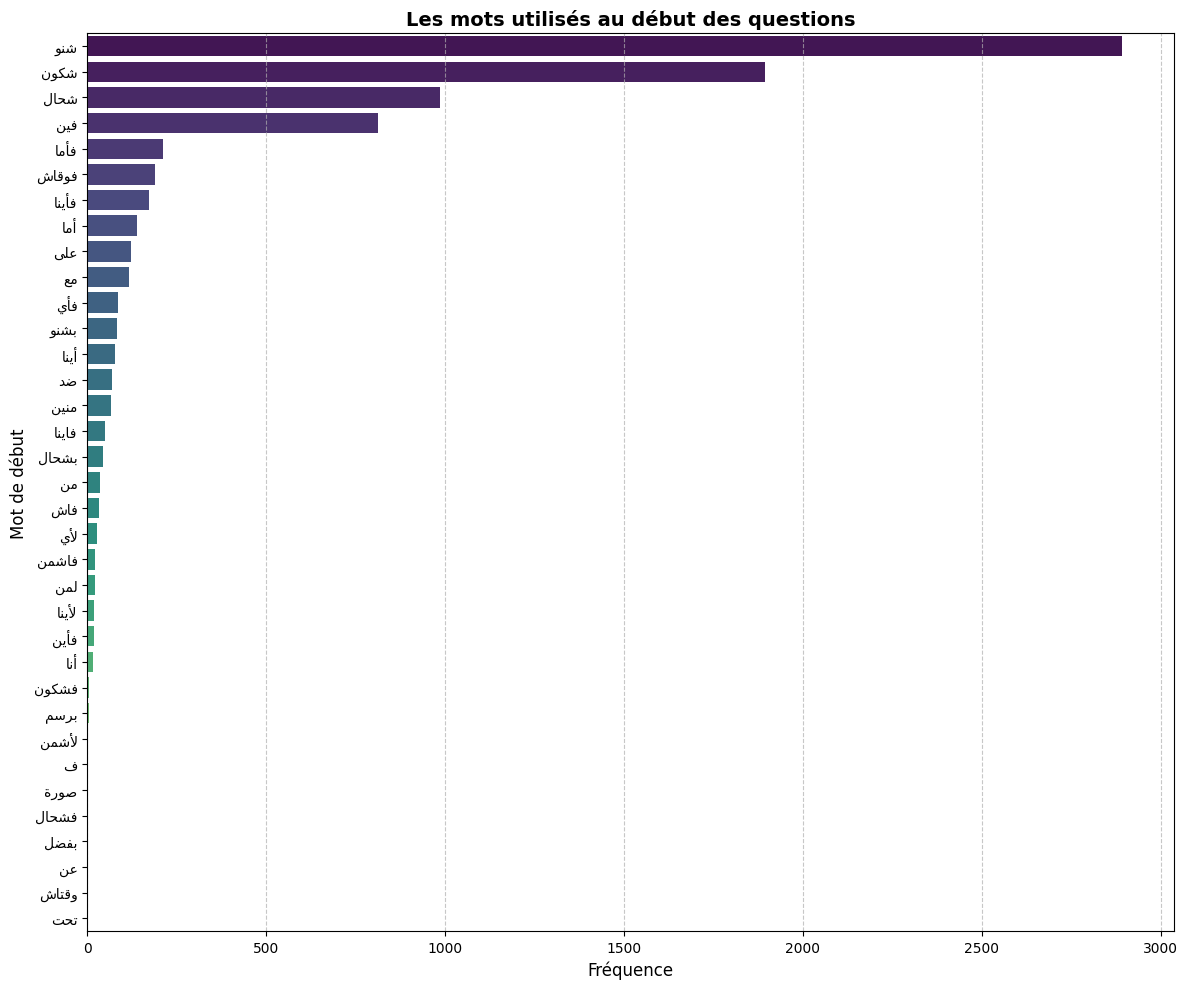

In [313]:
import matplotlib.pyplot as plt
import seaborn as sns

# Remplacez 'Question' par le nom exact de la colonne contenant vos questions
colonne_question = 'Question'

# Extraire le premier mot de chaque question (On gère les valeurs nulles et on met en minuscules pour standardiser)
df['debut_question'] = df[colonne_question].dropna().apply(
    lambda x: str(x).strip().split()[0].lower() if pd.notnull(x) and len(str(x).strip()) > 0 else None
)

# Compter les occurrences des  mots
top_debuts = df['debut_question'].value_counts()

# Appliquer fix_arabic à chaque label en utilisant une compréhension de liste
fixed_labels = [fix_arabic(label) for label in top_debuts.index]

# Visualiser les résultats
plt.figure(figsize=(12, 10))
sns.barplot(x=top_debuts.values, y=fixed_labels, palette='viridis')

plt.title('Les mots utilisés au début des questions', fontsize=14, fontweight='bold')
plt.xlabel('Fréquence', fontsize=12)
plt.ylabel('Mot de début', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

> - top 10 piechart

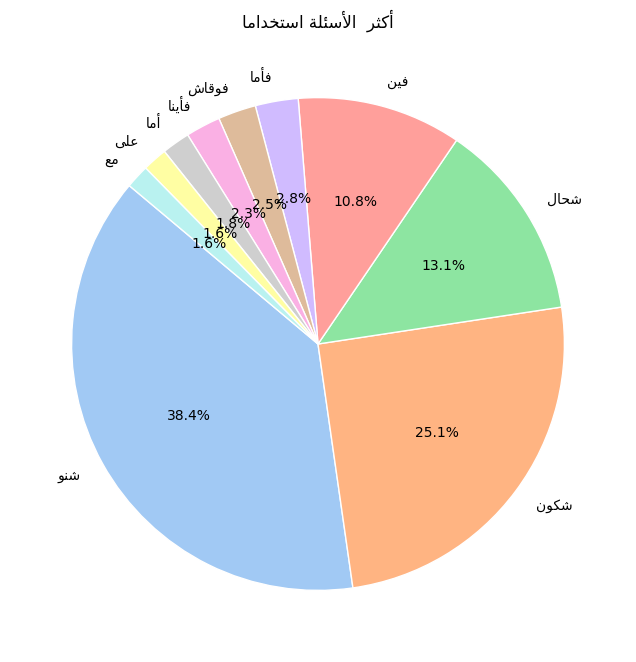

In [314]:
import matplotlib.pyplot as plt
# Prendre les 10 premiers mots pour que le diagramme reste lisible
top_debuts_pie = df['debut_question'].value_counts().head(10)

# 1. Appliquer fix_arabic à chaque label en utilisant une compréhension de liste
fixed_labels = [fix_arabic(label) for label in top_debuts_pie.index]

# Créer le diagramme circulaire
plt.figure(figsize=(10, 8))
plt.pie( 
    top_debuts_pie.values, 
    labels=fixed_labels,  # 2. Utiliser la nouvelle liste corrigée ici
    autopct='%1.1f%%',        
    startangle=140,           
    colors=sns.color_palette('pastel', len(top_debuts_pie)), 
    wedgeprops={'edgecolor': 'white', 'linewidth': 1} 
)

plt.title(fix_arabic("أكثر  الأسئلة استخداما"))

plt.show()

In [315]:
# number of unique values in debut_question column
print("Number of unique values in debut_question column:", df['debut_question'].nunique())
# display number of unique values in debut_question column that have less than 15 occurrences
print("Number of unique values in debut_question column that have less than 15 occurrences:",
       df['debut_question'].value_counts()[df['debut_question'].value_counts() < 15].count())



Number of unique values in debut_question column: 35
Number of unique values in debut_question column that have less than 15 occurrences: 10


## check rare questions

In [316]:
# Step 1: Calculate the frequencies of each 'debut_question'
counts = df['debut_question'].value_counts()


> - plus que ou egale 15 occurence

In [317]:

# 2. Filtrer pour ne garder que ceux qui ont un compte >= 15
frequent_debuts = counts[counts >= 15]
# 3. Convertir le résultat en une liste de paires (tuples)
paires_frequentes = list(frequent_debuts.items())
# 4. Afficher le résultat
for mot, compte in paires_frequentes:
    print(f"('{mot}', {compte})")

('شنو', 2892)
('شكون', 1894)
('شحال', 987)
('فين', 813)
('فأما', 212)
('فوقاش', 188)
('فأينا', 172)
('أما', 139)
('على', 122)
('مع', 117)
('فأي', 85)
('بشنو', 82)
('أينا', 78)
('ضد', 68)
('منين', 65)
('فاينا', 49)
('بشحال', 45)
('من', 36)
('فاش', 32)
('لأي', 26)
('فاشمن', 22)
('لمن', 22)
('لأينا', 20)
('فأين', 18)
('أنا', 16)


> - moins de 15

In [318]:

# 2. Filtrer pour ne garder que ceux qui ont un compte >= 15
frequent_debuts = counts[counts < 15]
# 3. Convertir le résultat en une liste de paires (tuples)
paires_frequentes = list(frequent_debuts.items())
# 4. Afficher le résultat
for mot, compte in paires_frequentes:
    print(f"('{mot}', {compte})")

('فشكون', 4)
('برسم', 4)
('لأشمن', 2)
('ف', 2)
('صورة', 1)
('فشحال', 1)
('بفضل', 1)
('عن', 1)
('وقتاش', 1)
('تحت', 1)


> - creation d'une liste des indices de mot avec moins de 15 occurences.

In [319]:

# Step 2: Extract the actual names (the index (cad: la valeur du mot)) of the questions that appear less than 15 times
rare_debuts = counts[counts < 15].index


# Step 3: Filter the DataFrame, take ONLY the 'id' column, and convert to a list
ids_rare = df[df['debut_question'].isin(rare_debuts)]['id'].tolist()


print("Number of total des mots rare IDs:", len(ids_rare))
print(ids_rare) # display the list of rare question IDs
print(list(rare_debuts)) # display the list of rare debut_question values

Number of total des mots rare IDs: 18
[1230, 1721, 1814, 2101, 3247, 3624, 4066, 4174, 4510, 4846, 5417, 5510, 5520, 6127, 6304, 6440, 6586, 8172]
['فشكون', 'برسم', 'لأشمن', 'ف', 'صورة', 'فشحال', 'بفضل', 'عن', 'وقتاش', 'تحت']


> voir les question populaire (>= 15 occurences)

In [320]:
viral_debuts = counts[counts >= 15].index
print(list(viral_debuts))

['شنو', 'شكون', 'شحال', 'فين', 'فأما', 'فوقاش', 'فأينا', 'أما', 'على', 'مع', 'فأي', 'بشنو', 'أينا', 'ضد', 'منين', 'فاينا', 'بشحال', 'من', 'فاش', 'لأي', 'فاشمن', 'لمن', 'لأينا', 'فأين', 'أنا']


> ##  🚩 fonction 1; pour voir le nombre doccurence de mot specific

In [321]:
count = df[df['debut_question'] == 'بشحال']['id'].count()

print(count)

45


> ##  🚩 fonction 2; pour extraire une lise des IDs d'un mot specifique

In [322]:
ids_extracted_bsh7ale = df[df['debut_question'] == 'بشحال']['id'].tolist()

# Afficher la liste extraite
print("Number of total 3lach IDs:", len(ids_extracted_bsh7ale))
print(ids_extracted_bsh7ale)

Number of total 3lach IDs: 45
[159, 294, 352, 624, 647, 884, 928, 1269, 1528, 1720, 1871, 2024, 2026, 2067, 2157, 2223, 2608, 2738, 2758, 3008, 3394, 3652, 4068, 4129, 4227, 4240, 4603, 4736, 4739, 4949, 5115, 5282, 5464, 5540, 5770, 5780, 5818, 6720, 7025, 7297, 7409, 7647, 7750, 8006, 8176]


> ##  🚩 fonction 3; pour extraire une lise des IDs d'un mot specifique

In [323]:
# Display the resulting DataFrame
print(f"Showing all rows where debut_question is 'أنا':")
display(df[df['debut_question'] == 'على'])

Showing all rows where debut_question is 'أنا':


,id,context,Question,Answer,debut_question
4,5,أفادت نادية فتاح علوي، وزيرة الاقتصاد والمالية...,على حساب أما قانون تقدر الحكومة تأطر الأسعار؟,قانون حرية الأسعار والمنافسة,على
12,13,أصدر طبيب أعصاب تحذيراً بشأن عادة شائعة متصلة ...,على اش حذر طبيب أعصاب بخصوص خطر الإصابة بالخرف؟,عادة شائعة متصلة بالنوم,على
164,165,حزب العدالة والتنمية خرج ببيان كيشبه أكثر لرقص...,على من اختار حزب العدالة والتنمية يركب بحسابات...,القضية الفلسطينية,على
223,224,طالبت المجموعة النيابية للعدالة والتنمية، بإحا...,على من بغات المجموعة النيابية للعدالة والتنمية...,اللجنة الوطنية لحماية المعطيات ذات الطابع الشخصي,على
247,248,أحالت الفرقة الجهوية للشرطة القضائية بولاية أم...,على من أحالت الفرقة الجهوية للشرطة القضائية ال...,الوكيل العام بمحكمة الاستئناف بالمدينة الحمرا,على
...,...,...,...,...,...
7927,7928,اعتبر جواد الياميق مدافع المنتخب الوطني المغرب...,على أي منتخب ربح المغرب فإقصائيات كاس العالم؟,النيجر,على
8023,8024,عبر كولو مواني لاعب يوفنتوس الطالياني على الفر...,على من توعد كولو مواني بالرباح فالجولة الثانية؟,الوداد,على
8044,8045,التقت “كود” مع أحد أشهر صناع الروجا على المستو...,على من ورث المعلم هشام السقاط حرفة صنيع الروجا؟,الأب ديالو,على
8107,8108,قدمت رئاسة الجمعية العامة التابعة للأمم المتحد...,على أي بند تعتمد مشروع القرار الخاص بنزاع الصح...,البند 58,على


> - ## plus ou egale 15 occurence

In [324]:

# 2. Filtrer pour ne garder que ceux qui ont un compte >= 15
frequent_debuts = counts[counts >= 15]
# 3. Convertir le résultat en une liste de paires (tuples)
paires_frequentes = list(frequent_debuts.items())
# 4. Afficher le résultat
for mot, compte in paires_frequentes:
    print(f"('{mot}', {compte})")

('شنو', 2892)
('شكون', 1894)
('شحال', 987)
('فين', 813)
('فأما', 212)
('فوقاش', 188)
('فأينا', 172)
('أما', 139)
('على', 122)
('مع', 117)
('فأي', 85)
('بشنو', 82)
('أينا', 78)
('ضد', 68)
('منين', 65)
('فاينا', 49)
('بشحال', 45)
('من', 36)
('فاش', 32)
('لأي', 26)
('فاشمن', 22)
('لمن', 22)
('لأينا', 20)
('فأين', 18)
('أنا', 16)


In [325]:
df_filtered = df[df['debut_question'].isin(frequent_debuts.index)].copy()

print(f"Nombre de lignes après filtrage: {len(df_filtered)}")

Nombre de lignes après filtrage: 8200


In [326]:
# Optionnel : sauvegarder le résultat
df_filtered.to_csv("QA-Labled-Data_filtered_15plus.csv", index=False, encoding="utf-8")

In [327]:
# Charger le dataset si ce n'est pas déjà fait
df = pd.read_csv("QA-Labled-Data_filtered_15plus.csv", encoding="utf-8")

# Calculer le début de chaque question
df['debut_question'] = (
    df['Question']
    .astype(str)
    .str.strip()
    .str.split()
    .str[0]
    .str.lower()
)

# Sélectionner une ligne exemple par début de question
exemples = (
    df.dropna(subset=['debut_question'])
      .groupby('debut_question', sort=False)
      .apply(lambda g: g.iloc[0])
      .reset_index(drop=True)
)

# Afficher chaque début et une question exemple
for _, row in exemples.iterrows():
    print(f"{row['debut_question']} -> {row['Question']} (id={row.get('id', 'n/a')})")

شنو -> شنو هي التهمة اللي موجهة لمصطفى لخصم رئيس جماعة إيموزار كندر؟ (id=1)
فأما -> فأما قناة عطى مسعد بولس التصريح ديالو؟ (id=2)
شكون -> شكون هي الجهة اللي أكدات بلي الأجهزة الكهربائية والإلكترونية محركات أساسية في التطور التكنولوجي؟ (id=3)
أما -> أما محكمة قررات تأخر أول جلسة ديال محاكمة إلياس المالكي؟ (id=4)
على -> على حساب أما قانون تقدر الحكومة تأطر الأسعار؟ (id=5)
شحال -> شحال هو العدد الإجمالي ديال الناس اللي دوزوا لكونكور ديال البوليس؟ (id=6)
فوقاش -> فوقاش غادي يكون الوقت ديال بث الحوار ديال ايمانويل ماكرون؟ (id=17)
فين -> فين غادي يتلعب الماتش ديال المنتخب المغربي ضد منتخب النيجر؟ (id=18)
مع -> مع من غادي يتلاقى بنيامين نتنياهو فواشنطن؟ (id=58)
أنا -> أنا إقليم اللي السلطات ديالو خدامة باش تواجه تداعيات التقلبات الجوية؟ (id=60)
فأينا -> فأينا حي طاحت فيه ديك الفاجعة ديال انهيار جوج بنايات؟ (id=72)
فأي -> فأي مدينة دارت جريدة “كود” جولة فالأحياء الشعبية؟ (id=82)
منين -> منين جاو الوفد الأمريكي لي تلاقاو مع أميرة حرمة الله؟ (id=88)
ضد -> ضد من خسر المنتخب المغربي لأقل من 17 عام

In [328]:
# Créer un masque pour les débuts suspects
mask_debut = df['debut_question'].isin(["فأما", "أما", "أنا", "فأي"])

# Créer un masque pour les expressions dans la question
question = df['Question'].astype(str)

mask_عن_من = question.str.contains("عن من", na=False)
mask_على = question.str.contains("على", na=False)
mask_أما = question.str.contains("أما", na=False)
mask_من_أما = question.str.contains("من أما", na=False)

# Masque final : début suspect OU expressions suspectes
mask_suspect = (
    mask_debut
    | mask_عن_من
    | (mask_على & mask_أما)
    | mask_من_أما
)

# Nouveau DataFrame avec les lignes suspectes seulement
df_suspect = df[mask_suspect].copy()

# Afficher un aperçu
print(f"Lignes suspectes trouvées : {len(df_suspect)}")
display(df_suspect.head(20))

Lignes suspectes trouvées : 466


,id,context,Question,Answer,debut_question
1,2,فتصريح لقناة العربية، قال مستشار شؤون الشرق ال...,فأما قناة عطى مسعد بولس التصريح ديالو؟,قناة العربية,فأما
3,4,علمت “كود” أن غرفة الجنح التلبسية بالمحكمة الا...,أما محكمة قررات تأخر أول جلسة ديال محاكمة إليا...,المحكمة الابتدائية بمدينة الجديدة,أما
4,5,أفادت نادية فتاح علوي، وزيرة الاقتصاد والمالية...,على حساب أما قانون تقدر الحكومة تأطر الأسعار؟,قانون حرية الأسعار والمنافسة,على
9,10,أجرى وزير الشؤون الخارجية الروسية، سيرگي لافرو...,فأما مدينة تلاقى ناصر بوريطة مع سيرگي لافروف؟,موسكو,فأما
22,23,واصل فريق الجيش الملكي حصد النتائج الإيجابية، ...,فأما تيران تلعب الماتش اللي ربح فيه الجيش الملكي؟,تيران القنيطرة,فأما
26,27,هرس واحد السائح كرسي مزيّن بمئات ديال حبيبات س...,فأما مدينة كاين هاد القصر التاريخي اللي تهرس ف...,مدينة فيرونا,فأما
45,46,قررت البوكسورة الجزائرية إيمان خليف المتوجة با...,فأما مدينة تدارت الأولمبياد لي ربحات فيها إيما...,باريس 2024,فأما
47,48,حكمات هيئة دالمحلفين فولاية مينيسوتا نهار الجم...,أما مادة قالت ديك الأم بلي منتجات التالك عرضات...,مادة الأسبستوس,أما
59,60,كتواصل السلطات المحلية بإقليم أزيلال، بتنسيق و...,أنا إقليم اللي السلطات ديالو خدامة باش تواجه ت...,إقليم أزيلال,أنا
69,70,علنات عائلة فرانسيسكو ريفيلا، الكيميائي الإيطا...,فأما نهار مات الكيميائي الإيطالي فرانسيسكو ريف...,يوم عيد الحب,فأما


In [329]:
def correct_question(row):
    question = row['Question']

    if isinstance(question, str):

        # فأما -> فإنا
        question = question.replace("فأما", "فإنا")

        # على ... أما -> remplacer أما par أشمن
        if "على" in question and "أما" in question:
            question = question.replace("أما", "أشمن")

        # أما -> أشمن
        question = question.replace("أما", "أشمن")

        # أنا -> إنا
        question = question.replace("أنا", "إنا")

        # فأي -> فأشمن
        question = question.replace("فأي", "فأشمن")

    return question


# Nouvelle colonne sans modifier l’original
df_suspect['corrected_question'] = df_suspect.apply(correct_question, axis=1)

# Sauvegarde
df_suspect.to_csv(
    "QA-Labled-Data_correct.csv",
    index=False,
    encoding="utf-8-sig"
)

In [330]:
df_suspect[['Question', 'corrected_question']].head(60)

,Question,corrected_question
1,فأما قناة عطى مسعد بولس التصريح ديالو؟,فإنا قناة عطى مسعد بولس التصريح ديالو؟
3,أما محكمة قررات تأخر أول جلسة ديال محاكمة إليا...,أشمن محكمة قررات تأخر أول جلسة ديال محاكمة إلي...
4,على حساب أما قانون تقدر الحكومة تأطر الأسعار؟,على حساب أشمن قانون تقدر الحكومة تأطر الأسعار؟
9,فأما مدينة تلاقى ناصر بوريطة مع سيرگي لافروف؟,فإنا مدينة تلاقى ناصر بوريطة مع سيرگي لافروف؟
22,فأما تيران تلعب الماتش اللي ربح فيه الجيش الملكي؟,فإنا تيران تلعب الماتش اللي ربح فيه الجيش الملكي؟
26,فأما مدينة كاين هاد القصر التاريخي اللي تهرس ف...,فإنا مدينة كاين هاد القصر التاريخي اللي تهرس ف...
45,فأما مدينة تدارت الأولمبياد لي ربحات فيها إيما...,فإنا مدينة تدارت الأولمبياد لي ربحات فيها إيما...
47,أما مادة قالت ديك الأم بلي منتجات التالك عرضات...,أشمن مادة قالت ديك الأم بلي منتجات التالك عرضا...
59,أنا إقليم اللي السلطات ديالو خدامة باش تواجه ت...,إنا إقليم اللي السلطات ديالو خدامة باش تواجه ت...
69,فأما نهار مات الكيميائي الإيطالي فرانسيسكو ريف...,فإنا نهار مات الكيميائي الإيطالي فرانسيسكو ريف...


In [331]:
# maintenant, on peut faire une vérification rapide pour voir combien de questions ont été modifiées
df_suspect['is_modified'] = df_suspect['Question'] != df_suspect['corrected_question']
print(f"Nombre de questions modifiées: {df_suspect['is_modified'].sum()} sur {len(df_suspect)}")

Nombre de questions modifiées: 466 sur 466


In [ ]:
# je veux caluler le taux d'error de mes corrections, c'est à dire le nombre de questions modifiées par rapport à 8200 lignesbdans dataset total
taux_error = (df_suspect[df_suspect['is_modified']].shape[0] / 8200) * 100
print(f"Taux d'erreur de correction: {taux_error:.2f}%")

Taux d'erreur de correction: 5.68%


In [333]:
colonne_question = 'corrected_question'

df_suspect['debut_question_corrige'] = (
    df_suspect[colonne_question]
    .astype(str)
    .str.strip()
    .str.split()
    .str[0]
    .str.lower()
)

display(df_suspect[['Question', 'corrected_question', 'debut_question_corrige']].head())

,Question,corrected_question,debut_question_corrige
1,فأما قناة عطى مسعد بولس التصريح ديالو؟,فإنا قناة عطى مسعد بولس التصريح ديالو؟,فإنا
3,أما محكمة قررات تأخر أول جلسة ديال محاكمة إليا...,أشمن محكمة قررات تأخر أول جلسة ديال محاكمة إلي...,أشمن
4,على حساب أما قانون تقدر الحكومة تأطر الأسعار؟,على حساب أشمن قانون تقدر الحكومة تأطر الأسعار؟,على
9,فأما مدينة تلاقى ناصر بوريطة مع سيرگي لافروف؟,فإنا مدينة تلاقى ناصر بوريطة مع سيرگي لافروف؟,فإنا
22,فأما تيران تلعب الماتش اللي ربح فيه الجيش الملكي؟,فإنا تيران تلعب الماتش اللي ربح فيه الجيش الملكي؟,فإنا


> visualizing only the row that have been corrected 

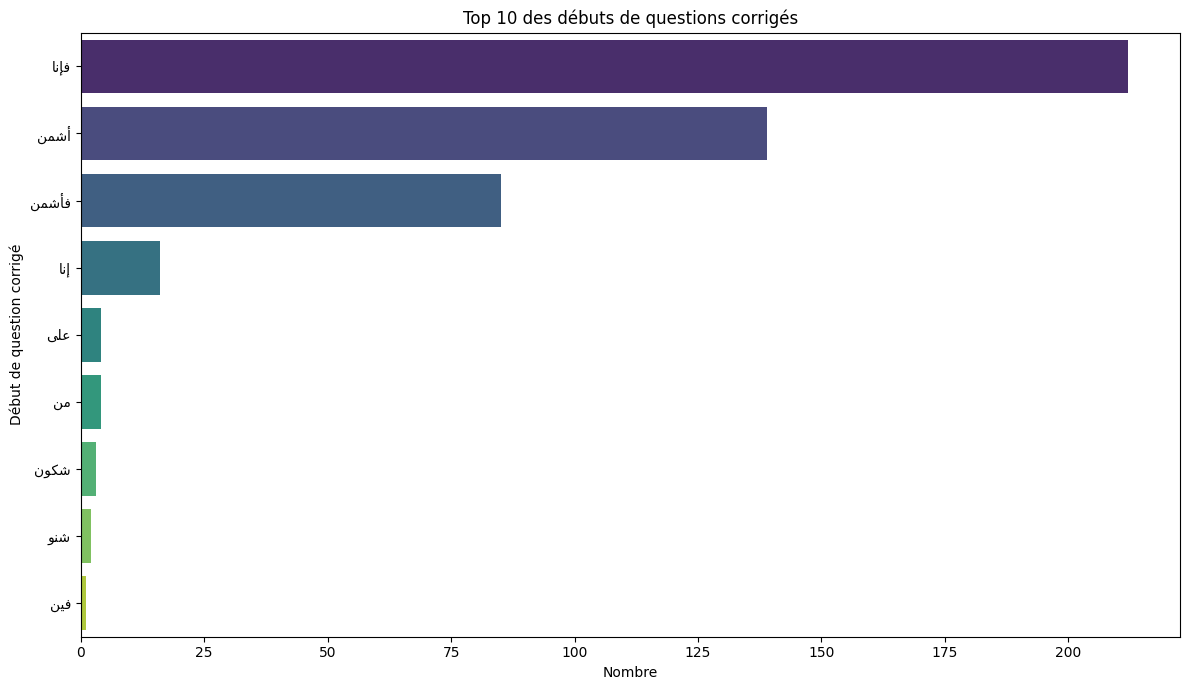

In [334]:
top_corrige = df_suspect['debut_question_corrige'].value_counts().head(10)
fixed_labels = [fix_arabic(lbl) for lbl in top_corrige.index]

plt.figure(figsize=(12, 7))
sns.barplot(x=top_corrige.values, y=fixed_labels, palette='viridis')
plt.title('Top 10 des débuts de questions corrigés')
plt.xlabel('Nombre')
plt.ylabel('Début de question corrigé')
plt.tight_layout()
plt.show()

In [335]:
df_suspect.head()

,id,context,Question,Answer,debut_question,corrected_question,is_modified,debut_question_corrige
1,2,فتصريح لقناة العربية، قال مستشار شؤون الشرق ال...,فأما قناة عطى مسعد بولس التصريح ديالو؟,قناة العربية,فأما,فإنا قناة عطى مسعد بولس التصريح ديالو؟,True,فإنا
3,4,علمت “كود” أن غرفة الجنح التلبسية بالمحكمة الا...,أما محكمة قررات تأخر أول جلسة ديال محاكمة إليا...,المحكمة الابتدائية بمدينة الجديدة,أما,أشمن محكمة قررات تأخر أول جلسة ديال محاكمة إلي...,True,أشمن
4,5,أفادت نادية فتاح علوي، وزيرة الاقتصاد والمالية...,على حساب أما قانون تقدر الحكومة تأطر الأسعار؟,قانون حرية الأسعار والمنافسة,على,على حساب أشمن قانون تقدر الحكومة تأطر الأسعار؟,True,على
9,10,أجرى وزير الشؤون الخارجية الروسية، سيرگي لافرو...,فأما مدينة تلاقى ناصر بوريطة مع سيرگي لافروف؟,موسكو,فأما,فإنا مدينة تلاقى ناصر بوريطة مع سيرگي لافروف؟,True,فإنا
22,23,واصل فريق الجيش الملكي حصد النتائج الإيجابية، ...,فأما تيران تلعب الماتش اللي ربح فيه الجيش الملكي؟,تيران القنيطرة,فأما,فإنا تيران تلعب الماتش اللي ربح فيه الجيش الملكي؟,True,فإنا


In [336]:
import pandas as pd
df=pd.read_csv("QA-Labled-Data_correct.csv", encoding="utf-8-sig")
df.drop(columns=['debut_question', 'Question'], inplace=True)
#renomer la colonne 'corrected_question' en 'Question'
df.rename(columns={'corrected_question': 'Question'}, inplace=True)
cols = ['id', 'context', 'Question', 'Answer']
df = df[cols]
df.head()

,id,context,Question,Answer
0,2,فتصريح لقناة العربية، قال مستشار شؤون الشرق ال...,فإنا قناة عطى مسعد بولس التصريح ديالو؟,قناة العربية
1,4,علمت “كود” أن غرفة الجنح التلبسية بالمحكمة الا...,أشمن محكمة قررات تأخر أول جلسة ديال محاكمة إلي...,المحكمة الابتدائية بمدينة الجديدة
2,5,أفادت نادية فتاح علوي، وزيرة الاقتصاد والمالية...,على حساب أشمن قانون تقدر الحكومة تأطر الأسعار؟,قانون حرية الأسعار والمنافسة
3,10,أجرى وزير الشؤون الخارجية الروسية، سيرگي لافرو...,فإنا مدينة تلاقى ناصر بوريطة مع سيرگي لافروف؟,موسكو
4,23,واصل فريق الجيش الملكي حصد النتائج الإيجابية، ...,فإنا تيران تلعب الماتش اللي ربح فيه الجيش الملكي؟,تيران القنيطرة


In [337]:
df.shape

(466, 4)

In [338]:
#sauveage du fichier final
df.to_csv("QA-Labled-Data_final_corrected.csv", index=False, encoding="utf-8-sig")

In [339]:
import pandas as pd
df=pd.read_csv("QA-Labled-Data_filtered_15plus.csv", encoding="utf-8-sig")
df.drop(columns=['debut_question'], inplace=True)

df.head()

,id,context,Question,Answer
0,1,حصلت “كود” على تفاصيل اتهام مصطفى لخصم رئيس جم...,شنو هي التهمة اللي موجهة لمصطفى لخصم رئيس جماع...,اختلاس وتبديد أموال عمومية
1,2,فتصريح لقناة العربية، قال مستشار شؤون الشرق ال...,فأما قناة عطى مسعد بولس التصريح ديالو؟,قناة العربية
2,3,أكد المجلس الاقتصادي والاجتماعي والبيئي أن الأ...,شكون هي الجهة اللي أكدات بلي الأجهزة الكهربائي...,المجلس الاقتصادي والاجتماعي والبيئي
3,4,علمت “كود” أن غرفة الجنح التلبسية بالمحكمة الا...,أما محكمة قررات تأخر أول جلسة ديال محاكمة إليا...,المحكمة الابتدائية بمدينة الجديدة
4,5,أفادت نادية فتاح علوي، وزيرة الاقتصاد والمالية...,على حساب أما قانون تقدر الحكومة تأطر الأسعار؟,قانون حرية الأسعار والمنافسة


In [340]:
df.shape

(8200, 4)

In [341]:
df.to_csv("QA-Labled-Data_filtered_15plus_final.csv", index=False, encoding="utf-8-sig")

In [342]:
import pandas as pd
# Lire les deux fichiers
correct = pd.read_csv("QA-Labled-Data_final_corrected.csv", encoding="utf-8-sig")
filtered = pd.read_csv("QA-Labled-Data_filtered_15plus_final.csv", encoding="utf-8")

# Retirer les lignes déjà présentes dans correct en se basant sur l'id
filtered_unique = filtered[~filtered["id"].isin(correct["id"])]

# Prendre seulement 400 lignes uniques
filtered_400 = filtered_unique.head(400).copy()

# Concaténer
combined = pd.concat([correct, filtered_400], ignore_index=True)
combined.head()


,id,context,Question,Answer
0,2,فتصريح لقناة العربية، قال مستشار شؤون الشرق ال...,فإنا قناة عطى مسعد بولس التصريح ديالو؟,قناة العربية
1,4,علمت “كود” أن غرفة الجنح التلبسية بالمحكمة الا...,أشمن محكمة قررات تأخر أول جلسة ديال محاكمة إلي...,المحكمة الابتدائية بمدينة الجديدة
2,5,أفادت نادية فتاح علوي، وزيرة الاقتصاد والمالية...,على حساب أشمن قانون تقدر الحكومة تأطر الأسعار؟,قانون حرية الأسعار والمنافسة
3,10,أجرى وزير الشؤون الخارجية الروسية، سيرگي لافرو...,فإنا مدينة تلاقى ناصر بوريطة مع سيرگي لافروف؟,موسكو
4,23,واصل فريق الجيش الملكي حصد النتائج الإيجابية، ...,فإنا تيران تلعب الماتش اللي ربح فيه الجيش الملكي؟,تيران القنيطرة


In [343]:
combined.shape

(866, 4)

In [344]:
#verifier les duplicates dans le combined dataset
duplicates = combined[combined.duplicated(subset=['id'], keep=False)]
print(f"Nombre de lignes dupliquées dans le dataset combiné : {len(duplicates)}")
print("IDs dupliqués :")
print(duplicates['id'].unique())

Nombre de lignes dupliquées dans le dataset combiné : 0
IDs dupliqués :
[]


In [345]:
# Enregistrer
combined.to_csv("QA-Labled-Data_combined_plus400.csv", index=False, encoding="utf-8-sig")

```bash
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢰⣆⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠰⢤⣶⣾⣿⣤⣴⠤⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⢠⡀⠀⠀⠀⠀⠀⠀⠀⣱⣿⣟⣿⠁⠀⠀⠀⠀⠀⠀⠀⠀⠀⣠⣿⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⢸⣧⡀⠀⠀⠀⠀⠀⠀⠟⠃⠀⠻⡄⠀⠀⠀⠀⠀⠀⠀⠀⣠⣿⣿⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠈⣿⣿⣆⠀⠀⠀⠀⠀⠀⣀⣀⡄⠀⠀⠐⢶⣦⣤⣤⣤⣴⡿⢻⣿⡀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⣿⣿⢻⣷⣄⣤⣶⣾⣿⣿⠋⠀⠀⠀⠀⠀⠙⢿⣏⡉⠉⠁⠘⠛⠿⣿⣿⣷⣶⠶⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⢀⣀⣤⣿⣷⠀⠙⠛⠋⢈⣽⡿⠋⠀⠀⠀⠀⠀⠀⠀⢨⣿⠟⠀⠀⠀⣾⡿⠟⠋⠉⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⣀⣴⣶⣿⣿⣟⣛⠉⠁⠀⠀⠀⠠⣻⣿⡁⠀⠀⠀⠀⠀⠀⠀⣰⣿⣿⣾⠿⣿⣆⣿⡇⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠉⠉⠛⠛⠻⢿⣿⡀⠀⣠⣄⣈⢻⣷⣦⠀⠀⠀⠀⠀⡼⠟⠋⡉⠀⠀⠈⠻⣿⡧⠀⣴⡄⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠘⣿⡇⣼⣿⠛⠿⠿⣟⣿⣷⣄⠀⠀⠀⠀⠀⢠⣿⡄⠀⠀⠀⠈⢳⣾⣿⡅⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠐⣿⣿⡿⠃⠀⠀⠀⠀⠈⠉⠛⠓⠀⠀⠙⠻⣿⣿⣿⠿⠛⠁⣠⣿⣿⣿⡇⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⣿⠟⠁⠀⠀⠀⠀⠀⢦⣤⣀⡀⠀⠀⠀⣰⠿⠓⢿⡇⢀⣼⣿⡿⣿⣿⡇⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠛⠀⠀⠀⠀⠀⠀⠀⠈⠿⣿⣷⣶⣦⣤⣭⣀⣀⠈⢃⣼⣿⡿⠃⣿⣿⡇⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠙⢿⣿⣿⡿⠿⣿⣿⣿⣿⣿⠏⠀⠀⣿⣿⡇⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢀⣦⠀⠀⠈⠻⣿⣿⣆⠀⠀⠉⠙⠃⠀⠀⠀⣿⣿⣿⣶⣤⣤⣄⣀⡀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠠⣤⣤⣾⣿⣤⣤⡤⠀⠘⢿⣿⣷⣄⠀⠀⠀⠀⠀⠀⠀⠉⠙⠛⠻⢿⣿⣿⣿⣿⣶⣦⣤⡄
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⣹⣿⣿⣯⠁⠀⠀⠀⣰⣿⣿⠏⠀⠀⠀⠀⠀⠀⢀⣀⣤⣴⣶⣿⣿⣿⠿⠟⠋⠉⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠛⠁⠈⠙⠇⠀⢀⣼⣿⡿⠃⠀⠀⣀⣀⠀⠀⠀⣿⣿⡿⠟⠋⠉⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⣠⣾⣿⣟⣠⣤⣶⣿⣿⣿⣧⡀⠀⣿⣿⣇⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⣼⣿⣿⣿⣿⠿⠟⠛⠉⠉⠻⣿⣿⣆⢽⣿⣿⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⢠⣾⣿⠛⠉⠁⠀⠀⠀⠀⠀⠀⠀⠙⣿⣿⣿⣿⣧⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠘⠉⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠈⢿⣿⣿⣿⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠹⣿⣿⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠈⠻⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀⠀
```